In [1]:
import os
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV , calibration_curve
from sklearn.metrics import accuracy_score, recall_score, precision_score ,roc_auc_score, average_precision_score, brier_score_loss

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from flaml import AutoML


In [2]:
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df = df.drop('customerID', axis=1)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

addon_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
              'TechSupport', 'StreamingTV', 'StreamingMovies']

def add_new_features(data):
    data['num_addons'] = (data[addon_cols] == 'Yes').sum(axis=1)
    data['auto_pay'] = data['PaymentMethod'].str.contains('automatic').astype(int)
    data['fiber_no_support'] = ((data['InternetService'] == 'Fiber optic') & (data['TechSupport'] != 'Yes')).astype(int)
    return data

df = add_new_features(df)
print(df.shape)

(7043, 23)


In [3]:
df = pd.get_dummies(df, dtype=int)

X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# scaling for logistic regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("train:", X_train.shape[0], "| test:", X_test.shape[0])

train: 5634 | test: 1409


In [5]:
results = []   # one row per model
probs = {}     # churn probabilities of every model on the test set

def check_model(name, prob):
    pred = (prob >= 0.5).astype(int)
    results.append([name,
                    accuracy_score(y_test, pred),
                    recall_score(y_test, pred),
                    precision_score(y_test, pred),
                    roc_auc_score(y_test, prob),
                    average_precision_score(y_test, prob)])
    probs[name] = prob
    print(f"{name:30s} roc auc: {roc_auc_score(y_test, prob):.4f}   pr auc: {average_precision_score(y_test, prob):.4f}")

In [7]:
# 1. logistic regression
lr = LogisticRegression(max_iter=5000)
lr.fit(X_train_scaled, y_train)
check_model("Logistic Regression", lr.predict_proba(X_test_scaled)[:, 1])

# 2. random forest
rf = RandomForestClassifier(n_estimators=210, max_depth=11, random_state=42)
rf.fit(X_train, y_train)
check_model("Random Forest", rf.predict_proba(X_test)[:, 1])

# 3. xgboost
xgb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)
xgb.fit(X_train, y_train)
check_model("XGBoost", xgb.predict_proba(X_test)[:, 1])

# 4. lightgbm
lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, random_state=42, verbose=-1)
lgbm.fit(X_train, y_train)
check_model("LightGBM", lgbm.predict_proba(X_test)[:, 1])

# 5. lightgbm with class_weight='balanced' (gives churners more importance while training)
lgbm_bal = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, class_weight='balanced', random_state=42, verbose=-1)
lgbm_bal.fit(X_train, y_train)
check_model("LightGBM (balanced weights)", lgbm_bal.predict_proba(X_test)[:, 1])

Logistic Regression            roc auc: 0.8409   pr auc: 0.6303
Random Forest                  roc auc: 0.8370   pr auc: 0.6486
XGBoost                        roc auc: 0.8427   pr auc: 0.6604
LightGBM                       roc auc: 0.8359   pr auc: 0.6413
LightGBM (balanced weights)    roc auc: 0.8389   pr auc: 0.6520


In [8]:
automl = AutoML()
automl.fit(X_train, y_train,
           task="classification",
           metric="roc_auc",
           estimator_list=["lgbm", "xgboost", "rf", "extra_tree"],
           eval_method="cv",
           n_splits=5,
           time_budget=60,
           seed=42,
           verbose=0)

flaml_model = automl.model.estimator
flaml_name = "FLAML (" + automl.best_estimator + ")"

print("best model found:", automl.best_estimator)
check_model(flaml_name, flaml_model.predict_proba(X_test)[:, 1])

best model found: lgbm
FLAML (lgbm)                   roc auc: 0.8473   pr auc: 0.6592


In [10]:
# the best cross-validation score flaml found for each algorithm
print("algorithm     best cross-validation roc auc")
for algorithm in automl.best_loss_per_estimator:
    best_auc = 1 - automl.best_loss_per_estimator[algorithm]
    print(f"{algorithm:12s}  {best_auc:.4f}")

print()
print("settings of the winning model:")
print(flaml_model)

algorithm     best cross-validation roc auc
lgbm          0.8507
xgboost       0.8498
rf            0.8419
extra_tree    0.8268

settings of the winning model:
LGBMClassifier(learning_rate=np.float64(0.06547995712832934), max_bin=31,
               min_child_samples=7, n_estimators=167, n_jobs=-1, num_leaves=4,
               reg_alpha=0.0009765625, reg_lambda=np.float64(18.60435206747652),
               verbose=-1)


In [11]:
# same search again with different seeds (30 seconds each)
for seed in [1, 2, 3]:
    test_automl = AutoML()
    test_automl.fit(X_train, y_train,
                    task="classification",
                    metric="roc_auc",
                    estimator_list=["lgbm", "xgboost", "rf", "extra_tree"],
                    eval_method="cv",
                    n_splits=5,
                    time_budget=30,
                    seed=seed,
                    verbose=0)
    print("seed", seed, "-> winner:", test_automl.best_estimator)

seed 1 -> winner: xgboost
seed 2 -> winner: xgboost
seed 3 -> winner: xgboost


In [12]:
comparison = pd.DataFrame(results, columns=['model', 'accuracy', 'recall', 'precision', 'roc_auc', 'pr_auc'])
comparison = comparison.set_index('model').sort_values('roc_auc', ascending=False).round(4)
comparison

,accuracy,recall,precision,roc_auc,pr_auc
model,,,,,
FLAML (lgbm),0.7999,0.5321,0.6503,0.8473,0.6592
XGBoost,0.8048,0.5241,0.6689,0.8427,0.6604
Logistic Regression,0.8041,0.5588,0.6531,0.8409,0.6303
Logistic Regression,0.8041,0.5588,0.6531,0.8409,0.6303
LightGBM (balanced weights),0.7637,0.7754,0.5380,0.8389,0.6520
Random Forest,0.7999,0.5187,0.6554,0.8370,0.6486
LightGBM,0.7999,0.5160,0.6565,0.8359,0.6413


In [13]:
# the test set is only 1409 customers, so scores move a bit by luck.
# bootstrap: draw 300 random samples (with repeats) from the test set and score every model on each sample
rng = np.random.RandomState(42)
y_arr = y_test.values

boot = {}
for name in probs:
    boot[name] = []

for i in range(300):
    idx = rng.randint(0, len(y_arr), len(y_arr))
    for name in probs:
        boot[name].append(roc_auc_score(y_arr[idx], probs[name][idx]))

# 95% interval for every model
names = list(probs.keys())
mid, low, high = [], [], []
for name in names:
    mid.append(roc_auc_score(y_arr, probs[name]))
    low.append(np.percentile(boot[name], 2.5))
    high.append(np.percentile(boot[name], 97.5))
    print(f"{name:30s} roc auc {mid[-1]:.4f}   95% interval [{low[-1]:.4f}, {high[-1]:.4f}]")

# how often does flaml beat logistic regression on the same samples?
diff = np.array(boot[flaml_name]) - np.array(boot["Logistic Regression"])
print()
print(f"{flaml_name} beats Logistic Regression in {(diff > 0).mean() * 100:.0f}% of the 300 samples")

Logistic Regression            roc auc 0.8409   95% interval [0.8216, 0.8617]
Random Forest                  roc auc 0.8370   95% interval [0.8153, 0.8569]
XGBoost                        roc auc 0.8427   95% interval [0.8238, 0.8638]
LightGBM                       roc auc 0.8359   95% interval [0.8158, 0.8582]
LightGBM (balanced weights)    roc auc 0.8389   95% interval [0.8185, 0.8595]
FLAML (lgbm)                   roc auc 0.8473   95% interval [0.8287, 0.8678]

FLAML (lgbm) beats Logistic Regression in 95% of the 300 samples


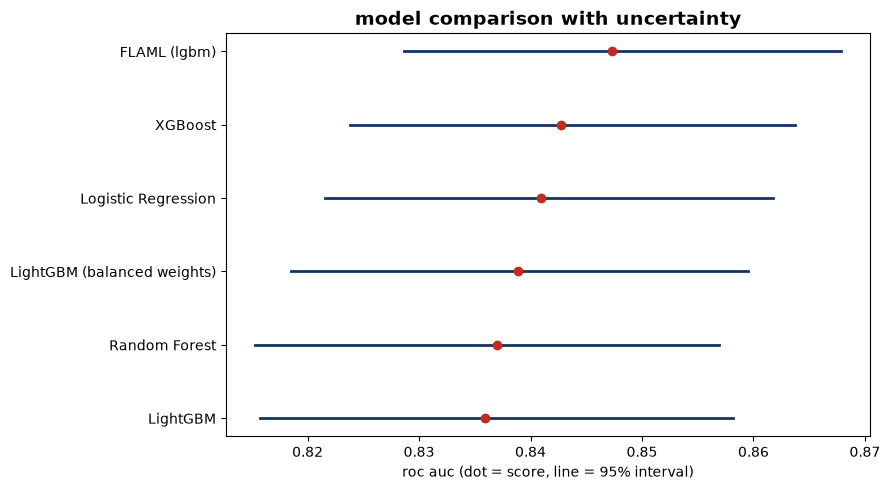

In [14]:
order = np.argsort(mid)
plt.figure(figsize=(9, 5))
for k, j in enumerate(order):
    plt.plot([low[j], high[j]], [k, k], color='#123463', linewidth=2)
    plt.plot(mid[j], k, 'o', color='#C42B1E')
plt.yticks(range(len(names)), [names[j] for j in order])
plt.xlabel('roc auc (dot = score, line = 95% interval)')
plt.title('model comparison with uncertainty', fontsize=14, fontweight='bold')
plt.tight_layout()
os.makedirs("images", exist_ok=True)
plt.savefig("images/model_comparison.png", bbox_inches="tight")
plt.show()

brier score before calibration: 0.1354
brier score after calibration : 0.135


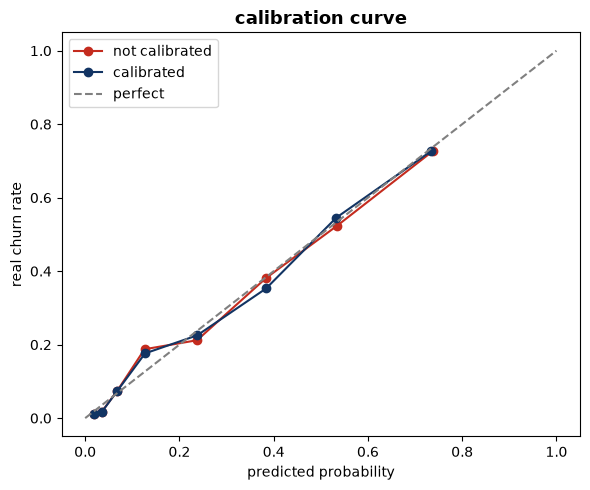

In [15]:
raw_prob = flaml_model.predict_proba(X_test)[:, 1]

# calibrated version of the same model
cal_model = CalibratedClassifierCV(clone(flaml_model), method='sigmoid', cv=5)
cal_model.fit(X_train, y_train)
cal_prob = cal_model.predict_proba(X_test)[:, 1]

# brier score = average squared error of the probabilities (lower is better)
print("brier score before calibration:", round(brier_score_loss(y_test, raw_prob), 4))
print("brier score after calibration :", round(brier_score_loss(y_test, cal_prob), 4))

plt.figure(figsize=(6, 5))
for prob, label, color in [(raw_prob, 'not calibrated', '#C42B1E'), (cal_prob, 'calibrated', '#123463')]:
    frac_pos, mean_pred = calibration_curve(y_test, prob, n_bins=8, strategy='quantile')
    plt.plot(mean_pred, frac_pos, 'o-', label=label, color=color)
plt.plot([0, 1], [0, 1], '--', color='grey', label='perfect')
plt.xlabel('predicted probability')
plt.ylabel('real churn rate')
plt.title('calibration curve', fontsize=13, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig("images/calibration_curve.png", bbox_inches="tight")
plt.show()

## Conclusion

- all models are close, see the README for the explanation
- I keep the flaml model for the app because it is small and fast